In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import timeit #Para medir el performance del modelo
from sklearn import datasets, linear_model

X, y= datasets.load_diabetes(return_X_y=True)
raw= X[:, None, 2] # Selecciona todas las filas de la tercera columna de X y agrega una dimensión extra, creando una matriz bidimensional raw

(array([32., 66., 98., 90., 61., 53., 23., 12.,  5.,  2.]),
 array([-1. , -0.8, -0.6, -0.4, -0.2,  0. ,  0.2,  0.4,  0.6,  0.8,  1. ]),
 <BarContainer object of 10 artists>)

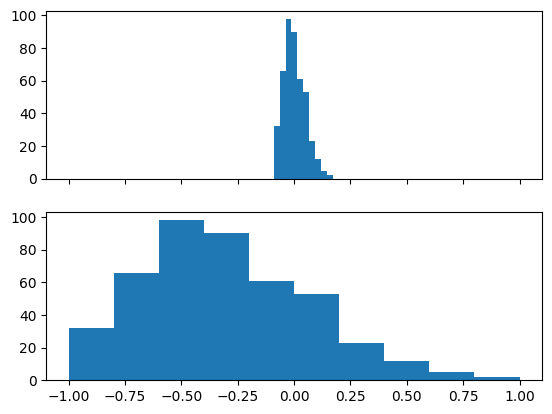

In [10]:
#REGLAS DE ESCALAMIENTO PARA DATOS LINEALES

#Maximo - Minimo
max_raw= max(raw)
min_raw= min(raw)
scaled= (2*raw-max_raw - min_raw)/(max_raw- min_raw)

fig, axes= plt.subplots(2,1, sharex= True) # sharex se usa para decir que compartan el eje x, la misma escala
axes[0].hist(raw)
axes[1].hist(scaled)

#Modelos para entrenamiento

def train_raw():
    linear_model.LinearRegression().fit(raw, y)

def train_scaled():
    linear_model.LinearRegression().fit(scaled, y)

raw_time= timeit.timeit(train_raw, number= 100) #Repetir la ejecucion 100 veces
scaled_time= timeit.timeit(train_scaled, number= 100) #Repetir la ejecucion 100 veces

print(f"train raw: {raw_time}")
print(f"train scaled: {scaled_time}")

print("\n")
if raw_time < scaled_time:
    print("No hubo reducción del tiempo en el entrenamiento del modelo con los datos escalados")
else:
    print("Hubo reducción del tiempo en el entrenamiento del modelo con los datos escalados")

train raw: 0.43029310000019905
train z_score: 0.32096760000058566


Hubo reducción del tiempo en el entrenamiento del modelo con los datos escalados


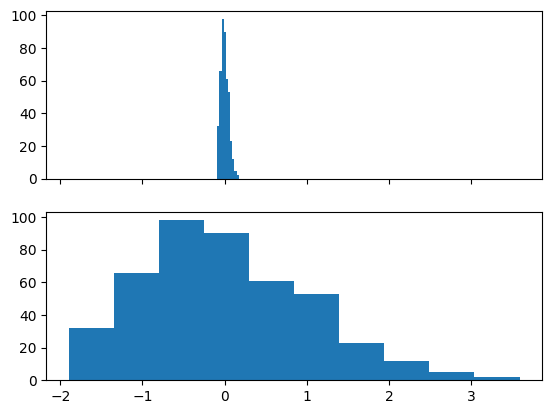

In [23]:
#Z-score
z_score= (raw-np.mean(raw))/(np.std(raw))

fig, axes= plt.subplots(2,1, sharex= True) # sharex se usa para decir que compartan el eje x, la misma escala
axes[0].hist(raw)
axes[1].hist(z_score)

#Entrenamiento del modelo 

def train_raw ():
    linear_model.LinearRegression().fit(raw, y)
def train_z_score ():
    linear_model.LinearRegression().fit(z_score, y)

raw_time= timeit.timeit(train_raw, number= 100)
z_score_time= timeit.timeit(train_z_score, number= 100)

print(f"train raw: {raw_time}")
print(f"train z_score: {z_score_time}")

print("\n")
if raw_time < z_score_time:
    print("No hubo reducción del tiempo en el entrenamiento del modelo con los datos escalados")
else:
    print("Hubo reducción del tiempo en el entrenamiento del modelo con los datos escalados")



<Axes: >

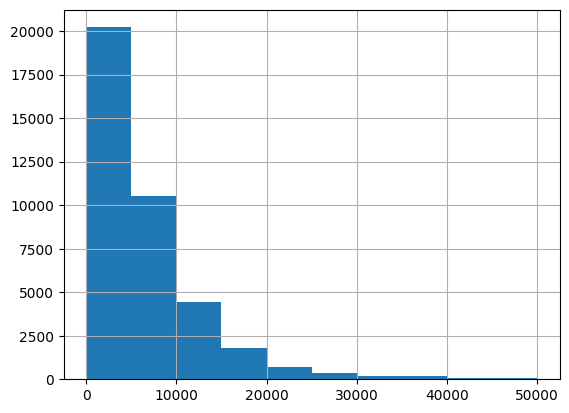

In [29]:
#REGLAS DE ESCALAMIENTO PARA DATOS NO LINEALES

import os 

os.chdir("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/estadistica_descriptiva/")

df= pd.read_csv("cars.csv")

df.price_usd.hist() #En la grafica se puede evidenciar que la distribucion esta fuertemente sesgada

<Axes: >

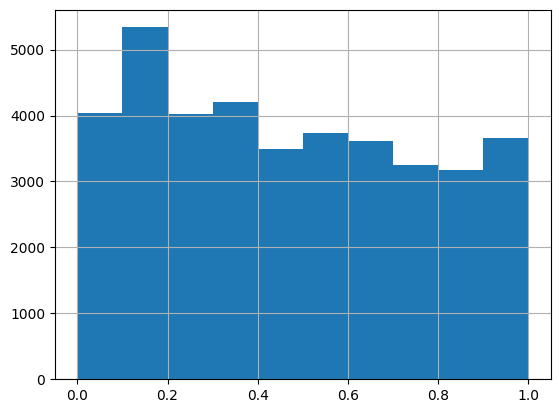

In [31]:
#Transformacion con tanh(x)
p= 10000
df.price_usd.apply(lambda x: np.tanh(x/p)).hist() #Se distribuyen los datos de manera uniforme con la funcion tangente hiperbolica

[[ 1.00671141 -0.11835884  0.87760447  0.82343066]
 [-0.11835884  1.00671141 -0.43131554 -0.36858315]
 [ 0.87760447 -0.43131554  1.00671141  0.96932762]
 [ 0.82343066 -0.36858315  0.96932762  1.00671141]]


<Axes: >

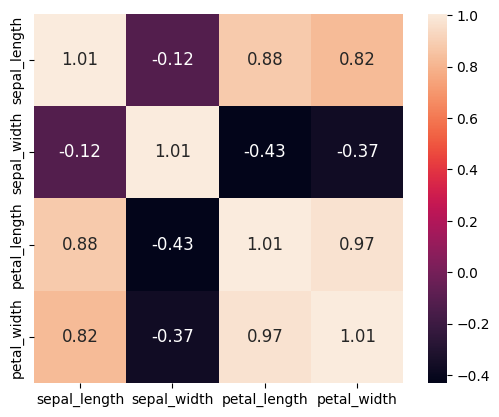

In [22]:
#CORRELACIONES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.preprocessing import StandardScaler

iris= sns.load_dataset("iris")

#sns.pairplot(iris)
#sns.pairplot(iris, hue= "species")

#Escalar los datos
scaler= StandardScaler() # Iniciar el StandardScaler
scaled= scaler.fit_transform(
    iris[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]) #Para estandarizar los las columnas con datos que yo quiero 

scaled.T #Transporner la matriz

covariance_matriz= np.cov(scaled.T)
print(covariance_matriz)

sns.heatmap(covariance_matriz,
            cbar= True,
            annot= True,
            square= True,
            fmt= ".2f",
            annot_kws= {"size": 12},
            yticklabels= ['sepal_length', 'sepal_width', 'petal_length', 'petal_width'],
            xticklabels= ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
)